# V3 — Post-hoc Token-Bigram Stealing-Guided Word Substitution

**Trustworthy AI seminar — Break the Watermark!** · Reproducible CPU experiment · No LLaDA 8B generation weights required.

**Question.** Can bigrams of **LLaDA tokenizer IDs, computed after generation from saved completion text**, identify word-substitution positions better than V1 (word unigram) and V2 (word bigram)?

**Threat model.** Learning uses only paired WM/NoWM `completion` strings. Neither `ages`, `mask`, `token_color`, nor detection results are features for learning. Detection results are used for evaluation only. The token IDs here are **post-hoc retokenizations**, **not** the diffusion generation trajectory or original token sequence.

**Three separate comparisons:**
1. **Strict matched counts:** each main method substitutes exactly `min(target, n_V3, n_V2, n_V1)` words **per text**. Pools need not match; differences combine ranking + eligibility.
2. **Shared-candidate pool:** V1, V2, V3 and random select from *exactly the same eligible word positions*, and edit `min(target, n_common)`. This isolates **ranking** within that restricted pool.
3. **Descriptive hybrid:** V3 → V2 → V1 fill. **Never compare its ASR at the same nominal ratio as if its real edit count were equal.**

10 stratified, overlapping splits of 400/200 prompt pairs; minimum pair support 2 or 5; target word-edit ratios 10–50%. All analyses exploratory: these 600 examples have already informed V1/V2. No semantic-quality measurement is included.

## 1 — Setup, versioned configuration, and tokenizer probe

The original detector’s `load_detector` loads the **same LLaDA tokenizer** used for watermark detection. Token IDs are used for statistics; word substitutions remain WordNet-based for comparison with V1/V2. Token-to-word mapping uses fast-tokenizer offsets when available, otherwise an exact **full-text retokenization difference probe** (documented in the manifest).

In [15]:
import hashlib
import importlib.metadata
import json
import math
import random
import re
import sys
import tempfile
import time
from collections import Counter, defaultdict
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
from IPython.display import display
from nltk.corpus import wordnet
from scipy.stats import binomtest
from tqdm.auto import tqdm


def find_project_root(start: Path) -> Path:
    for folder in (start, *start.parents):
        if (folder / "src" / "detection.py").is_file() and (
            folder / "results" / "Cleaned Data"
        ).is_dir():
            return folder
    raise FileNotFoundError("Run from within the project containing src/detection.py and results/Cleaned Data")

ROOT = find_project_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from detection import detect, load_detector, load_jsonl

EXPERIMENT_ID = "v3_posthoc_token_bigram_v1_2026_11_21"
SPLIT_SEEDS = [42, 100, 101, 102, 103, 104, 105, 106, 107, 108]
MIN_SUPPORTS = [2, 5]
RATIOS = [0.1, 0.2, 0.3, 0.4, 0.5]
ALPHA = 0.5
REFERENCE_SEED = 42
REFERENCE_SUPPORT = 2

# Pilot: RUN_SPLIT_SEEDS = [42]; RUN_SUPPORTS = [2]. Resume full configuration afterwards.
RUN_SPLIT_SEEDS = SPLIT_SEEDS
RUN_SUPPORTS = MIN_SUPPORTS              # PILOT first; set = MIN_SUPPORTS for full run
STORE_ATTACKED_TEXT = False
MAX_GUIDED_SYNONYMS = 16    # deterministic subset for tractable full-text retokenization

METHODS_MATCHED = [
    "v3_sum_random", "v3_mean_random", "v3_max_random", "v3_sum_guided",
    "v3_random_pool", "v2_sum_random_matched", "v1_score_random_matched",
    "random_wordnet_matched",
]
METHODS_COMMON = [
    "v3_common_sum_random", "v2_common_sum_random", "v1_common_score_random",
    "random_common_pool",
]
METHODS_DESCRIPTIVE = ["v3_hybrid_random"]
METHODS = METHODS_MATCHED + METHODS_COMMON + METHODS_DESCRIPTIVE
WORD_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?")

OUT_DIR = ROOT / "results" / "attacks" / "stealing_guided_v3_token_bigram"
CHECKPOINT_DIR = OUT_DIR / "checkpoints"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

try:
    assert wordnet.synsets("important")
except LookupError as exc:
    raise RuntimeError("NLTK WordNet missing. Run `import nltk; nltk.download('wordnet')` in .venv") from exc

assert set(RUN_SPLIT_SEEDS).issubset(SPLIT_SEEDS)
assert set(RUN_SUPPORTS).issubset(MIN_SUPPORTS)
assert MAX_GUIDED_SYNONYMS >= 1

tokenizer, detector = load_detector(ROOT)
PROBE_TEXT = "The model generates reliable answers."
try:
    _probe = tokenizer(PROBE_TEXT, add_special_tokens=False, return_offsets_mapping=True)
    _probe_ids = list(_probe["input_ids"])
    _probe_offsets = list(_probe["offset_mapping"])
    FAST_OFFSETS = (len(_probe_ids) == len(_probe_offsets) and
                    any(int(b) > int(a) for a, b in _probe_offsets))
except (TypeError, ValueError, KeyError, NotImplementedError):
    FAST_OFFSETS = False
ALIGNMENT_MODE = "token_offsets" if FAST_OFFSETS else "retokenized_difference_probe"

print("Project root:", ROOT)
print("Output folder:", OUT_DIR)
print("Tokenizer:", tokenizer.name_or_path, type(tokenizer).__name__)
print("Post-hoc token-word alignment:", ALIGNMENT_MODE)
print("Pilot/full splits:", RUN_SPLIT_SEEDS, "| supports:", RUN_SUPPORTS)

Project root: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking
Output folder: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v3_token_bigram
Tokenizer: GSAI-ML/LLaDA-8B-Instruct TokenizersBackend
Post-hoc token-word alignment: token_offsets
Pilot/full splits: [42, 100, 101, 102, 103, 104, 105, 106, 107, 108] | supports: [2, 5]


## 2 — Source data, paired splits, immutable experiment provenance

Training pairs are selected by the same split function as V2. No held-out test text is used in its split’s WM/NoWM frequency estimates. The existing baseline is used only to determine which test texts were originally detected.

In [16]:
WM_PATH = ROOT / "results" / "Cleaned Data" / "watermarked_600.jsonl"
NOWM_PATH = ROOT / "results" / "Cleaned Data" / "unwatermarked_600.jsonl"
BASELINE_PATH = ROOT / "results" / "attacks" / "baseline_original.jsonl"
DETECTION_PY = ROOT / "src" / "detection.py"

wm = load_jsonl(WM_PATH)
no_wm = load_jsonl(NOWM_PATH)
baseline_rows = load_jsonl(BASELINE_PATH)
assert len(wm) == len(no_wm) == len(baseline_rows) == 600
baseline_by_idx = {int(r["idx"]): r for r in baseline_rows}
assert set(baseline_by_idx) == set(range(600)), "Baseline must contain unique indices 0..599"


def dataset_id(row):
    return row["dataset_name"].split("_batch_")[0]


groups = defaultdict(list)
for idx in range(600):
    assert wm[idx]["prompt"] == no_wm[idx]["prompt"] == baseline_by_idx[idx]["prompt"]
    assert dataset_id(wm[idx]) == dataset_id(no_wm[idx])
    assert wm[idx]["completion"] and no_wm[idx]["completion"]
    groups[dataset_id(wm[idx])].append(idx)
assert len(groups) == 3 and sorted(map(len, groups.values())) == [200, 200, 200]


def make_split(seed):
    rng = random.Random(seed)
    train, test = [], []
    for j, (_, original_indices) in enumerate(sorted(groups.items())):
        indices = original_indices.copy()
        rng.shuffle(indices)
        n_train = 134 if j == 0 else 133
        train.extend(indices[:n_train])
        test.extend(indices[n_train:])
    train, test = sorted(train), sorted(test)
    assert len(train) == 400 and len(test) == 200
    assert set(train).isdisjoint(test) and set(train) | set(test) == set(range(600))
    return train, test



def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for part in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(part)
    return h.hexdigest()

input_hashes = {str(p.relative_to(ROOT)): file_sha256(p)
                for p in [WM_PATH, NOWM_PATH, BASELINE_PATH, DETECTION_PY]}

# Ensure tokenizer identity is frozen across a resumed experiment.
_token_vocab = sorted(tokenizer.get_vocab().items(), key=lambda item: item[0])
_tokenizer_hash = hashlib.sha256(json.dumps(_token_vocab, ensure_ascii=False).encode("utf-8")).hexdigest()
del _token_vocab
try:
    _transformers_version = importlib.metadata.version("transformers")
except importlib.metadata.PackageNotFoundError:
    _transformers_version = "unknown"

config = {
    "experiment_id": EXPERIMENT_ID,
    "split_seeds": SPLIT_SEEDS, "min_supports": MIN_SUPPORTS,
    "ratios": RATIOS, "alpha": ALPHA,
    "methods_matched": METHODS_MATCHED,
    "methods_common_pool": METHODS_COMMON,
    "methods_descriptive": METHODS_DESCRIPTIVE,
    "store_attacked_text": STORE_ATTACKED_TEXT,
    "max_guided_synonyms": MAX_GUIDED_SYNONYMS,
    "tokenizer_name": str(tokenizer.name_or_path),
    "tokenizer_class": type(tokenizer).__name__,
    "tokenizer_vocab_sha256": _tokenizer_hash,
    "transformers_version": _transformers_version,
    "nltk_version": importlib.metadata.version("nltk"),
    "alignment_mode": ALIGNMENT_MODE,
    "add_special_tokens": False,
    "input_sha256": input_hashes,
    "notes": "Post-hoc LLaDA tokenizer IDs; WordNet word-level edits; only completion text features",
}
config_path = OUT_DIR / "config.json"
if config_path.exists():
    assert json.loads(config_path.read_text(encoding="utf-8")) == config, (
        "Configuration/input/tokenizer fingerprint differs. Do NOT reuse checkpoints. "
        "Use a new EXPERIMENT_ID and output folder for a new experiment."
    )
    print("Existing configuration verified: safe to resume")
else:
    config_path.write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
    print("New configuration saved")

train42, test42 = make_split(42)
print("Paired inputs:", len(wm), "+", len(no_wm))
print("Split 42:", len(train42), "train /", len(test42), "test /",
      sum(bool(baseline_by_idx[i]["detected"]) for i in test42), "originally detected")
print("Datasets:", {k: len(v) for k, v in sorted(groups.items())})

Existing configuration verified: safe to resume
Paired inputs: 600 + 600
Split 42: 400 train / 200 test / 195 originally detected
Datasets: {'2-1_longform_qa': 200, '2-2_finance_qa': 200, '5-1_alpacafarm': 200}


## 3 — Exact V1/V2 word statistics + V3 post-hoc token-bigram model

Same word regex, WordNet synonym set, split, smoothing and `MIN_SUPPORT` semantics as V2. For V3, learn counts of consecutive **token IDs** on train WM and train NoWM. Each word obtains a score from all **observed, support-qualified token bigrams touching its token span**; we test the **sum**, **mean**, and **maximum** to diagnose tokenization-length bias. A bigram not observed above support is **unknown**, not automatically a favorable synonym replacement.

In [17]:
def tokenize_words(text):
    return WORD_PATTERN.findall(text.lower())


@lru_cache(maxsize=None)
def get_synonyms(word):
    candidates = set()
    for synset in wordnet.synsets(word):
        for lemma in synset.lemmas():
            candidate = lemma.name().lower()
            if candidate != word and re.fullmatch(r"[a-z]+", candidate):
                candidates.add(candidate)
    return tuple(sorted(candidates))


def smoothed_log_ratio(wm_counts, no_counts, alpha):
    vocabulary = set(wm_counts) | set(no_counts)
    v = len(vocabulary)
    if not v:
        raise ValueError("Empty training corpus")
    n_wm = sum(wm_counts.values())
    n_no = sum(no_counts.values())
    scores = {
        item: math.log(((wm_counts[item] + alpha) / (n_wm + alpha * v)) /
                       ((no_counts[item] + alpha) / (n_no + alpha * v)))
        for item in vocabulary
    }
    return scores


def learn_word_statistics(train_ids):
    wc_wm, wc_no, bc_wm, bc_no = Counter(), Counter(), Counter(), Counter()
    for idx in train_ids:
        wm_words = tokenize_words(wm[idx]["completion"])
        no_words = tokenize_words(no_wm[idx]["completion"])
        wc_wm.update(wm_words)
        wc_no.update(no_words)
        bc_wm.update(zip(wm_words[:-1], wm_words[1:]))
        bc_no.update(zip(no_words[:-1], no_words[1:]))
    return {
        "word_wm": wc_wm, "word_no": wc_no,
        "bigram_wm": bc_wm, "bigram_no": bc_no,
        "word_scores": smoothed_log_ratio(wc_wm, wc_no, ALPHA),
        "bigram_scores": smoothed_log_ratio(bc_wm, bc_no, ALPHA),
    }


def build_v1_dictionary(statistics, support):
    wm_counts = statistics["word_wm"]
    no_counts = statistics["word_no"]
    scores = statistics["word_scores"]
    dictionary = {}
    for word in sorted(scores):
        if wm_counts[word] + no_counts[word] < support or scores[word] <= 0:
            continue
        choices = [syn for syn in get_synonyms(word)
                   if syn in scores
                   and wm_counts[syn] + no_counts[syn] >= support
                   and scores[syn] < scores[word]]
        if choices:
            best = min(choices, key=lambda s: scores[s])
            dictionary[word] = {
                "replacement": best,
                "score": scores[word],
                "gain": scores[word] - scores[best],
            }
    return dictionary


def supported_bigram_score(statistics, bigram, support):
    n = statistics["bigram_wm"][bigram] + statistics["bigram_no"][bigram]
    return statistics["bigram_scores"].get(bigram) if n >= support else None


def collect_positions(text, statistics, support, v1_dict):
    matches = list(WORD_PATTERN.finditer(text.lower()))
    words = [m.group() for m in matches]
    v2, v1, all_wordnet = [], [], []
    for i, match in enumerate(matches):
        word = words[i]
        options = get_synonyms(word)
        if not options:
            continue
        base = {
            "word_index": i, "start": match.start(), "end": match.end(),
            "original": word, "prev": words[i - 1] if i else None,
            "next": words[i + 1] if i + 1 < len(words) else None,
        }
        all_wordnet.append(base)
        if word in v1_dict:
            v1.append({**base, "score_v1": v1_dict[word]["score"]})
        local_scores = []
        if i:
            score = supported_bigram_score(statistics, (words[i - 1], word), support)
            if score is not None:
                local_scores.append(score)
        if i + 1 < len(words):
            score = supported_bigram_score(statistics, (word, words[i + 1]), support)
            if score is not None:
                local_scores.append(score)
        s = sum(local_scores)
        if local_scores and s > 0:
            v2.append({**base, "score_sum": s,
                       "score_max": max(local_scores),
                       "n_observed_contexts": len(local_scores)})
    v2.sort(key=lambda p: -p["score_sum"])  # Python stable sort = tie by text order
    v1.sort(key=lambda p: -p["score_v1"])
    return len(matches), v2, v1, all_wordnet

def tokenize_ids(text):
    return tuple(int(v) for v in tokenizer(text, add_special_tokens=False)["input_ids"])


def token_bigram_counter(ids):
    return Counter(zip(ids[:-1], ids[1:]))


# Scores depend on training examples, not on support (support is applied at lookup).
def learn_statistics(train_ids):
    stats = learn_word_statistics(train_ids)
    token_wm, token_no = Counter(), Counter()
    for idx in train_ids:
        token_wm.update(token_bigram_counter(tokenize_ids(wm[idx]["completion"])))
        token_no.update(token_bigram_counter(tokenize_ids(no_wm[idx]["completion"])))
    stats.update({
        "token_bigram_wm": token_wm,
        "token_bigram_no": token_no,
        "token_bigram_scores": smoothed_log_ratio(token_wm, token_no, ALPHA),
    })
    return stats


def supported_token_bigram_score(stats, pair, support):
    count = stats["token_bigram_wm"][pair] + stats["token_bigram_no"][pair]
    return stats["token_bigram_scores"].get(pair) if count >= support else None


def stable_int(*parts):
    blob = "::".join(map(str, parts)).encode("utf-8")
    return int.from_bytes(hashlib.blake2b(blob, digest_size=8).digest(), "big")


def differing_token_span(old_ids, new_ids):
    """Smallest changed interval in each token sequence, found via shared prefix/suffix."""
    pre = 0
    while pre < min(len(old_ids), len(new_ids)) and old_ids[pre] == new_ids[pre]:
        pre += 1
    suf = 0
    while (suf < len(old_ids) - pre and suf < len(new_ids) - pre and
           old_ids[len(old_ids) - 1 - suf] == new_ids[len(new_ids) - 1 - suf]):
        suf += 1
    return pre, len(old_ids) - suf, len(new_ids) - suf


def touching_pair_indices(n_ids, start_token, end_token_exclusive):
    """Pair index j refers to IDs[j], IDs[j+1]; include both boundary edges."""
    if n_ids < 2:
        return ()
    # Works even if a changed segment becomes zero tokens.
    left = max(0, start_token - 1)
    right = min(n_ids - 2, end_token_exclusive)
    return tuple(range(left, right + 1)) if left <= right else ()


def token_edges_for_words(text, matches, ids):
    """Word -> affected token-pair indices, using full-completion tokenization."""
    if FAST_OFFSETS:
        batch = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
        offsets = [(int(a), int(b)) for a, b in batch["offset_mapping"]]
        assert tuple(int(t) for t in batch["input_ids"]) == ids
        assert len(offsets) == len(ids)
        output = []
        for match in matches:
            inside = [i for i, (a, b) in enumerate(offsets)
                      if a < b and a < match.end() and b > match.start()]
            if inside:
                output.append(touching_pair_indices(len(ids), min(inside), max(inside) + 1))
            else:
                # Rare offset anomaly: fall back locally instead of silently dropping a word.
                output.append(_probe_word_edges(text, match, ids))
        return output
    return [_probe_word_edges(text, match, ids) for match in matches]


def _probe_word_edges(text, match, ids):
    """No offsets: replace ONE span with a sentinel and retokenize the full completion."""
    probed = text[:match.start()] + "uniquexyzprobe" + text[match.end():]
    probe_ids = tokenize_ids(probed)
    pre, end_old, _ = differing_token_span(ids, probe_ids)
    return touching_pair_indices(len(ids), pre, end_old)


def collect_all_positions(text, stats, support, v1_dict):
    # V1/V2 logic below is IDENTICAL to V2's collect_positions.
    n_words, v2, v1, all_wordnet = collect_positions(text, stats, support, v1_dict)
    matches = list(WORD_PATTERN.finditer(text.lower()))
    ids = tokenize_ids(text)
    edges_by_word = token_edges_for_words(text, matches, ids)
    v3 = []
    n_known_pairs = 0
    n_local_pairs = 0
    for position in all_wordnet:
        j = position["word_index"]
        edges = edges_by_word[j]
        values = [supported_token_bigram_score(stats, (ids[e], ids[e + 1]), support)
                  for e in edges]
        known = [float(value) for value in values if value is not None]
        n_known_pairs += len(known)
        n_local_pairs += len(values)
        if known and sum(known) > 0:
            v3.append({**position, "score_sum": sum(known),
                       "score_mean": float(np.mean(known)), "score_max": max(known),
                       "n_supported_token_pairs": len(known),
                       "n_touching_token_pairs": len(edges)})
    v3.sort(key=lambda p: -p["score_sum"])
    v2_ix = {p["word_index"] for p in v2}
    v1_ix = {p["word_index"] for p in v1}
    common_ix = {p["word_index"] for p in v3} & v2_ix & v1_ix
    return {
        "n_words": n_words, "n_tokens": len(ids), "v3": v3,
        "v2": v2, "v1": v1, "wordnet": all_wordnet,
        "common_indices": common_ix,
        "n_covered_union": len({p["word_index"] for p in (v3 + v2 + v1)}),
        "n_supported_local_pairs": n_known_pairs, "n_local_pairs": n_local_pairs,
        "original_token_ids": ids,
    }

## 4 — Attack variants and exact per-text matching

**Main methods (8):** V3 sum/mean/max, V3 sum guided (retokenize each candidate synonym in the **entire** completion), V3 random eligible pool, V2 sum, V1 score, global WordNet random. The six other-than-guided/length-control methods use the identical deterministic WordNet synonym for any given `(split, ratio, text, word index)`.

**Common pool (4):** V3 sum, V2 sum, V1 score, random positions restricted to the same `V1 ∩ V2 ∩ V3` pool.

**Hybrid (1, descriptive):** V3 positions first, followed by V2 and then V1 without replacing any position twice. Its edit counts are **not** matched to the other methods.

**Guided warning:** WordNet synonyms are a fixed, deterministic **sample of up to 16** per word for computational tractability. For each proposal, the *whole changed sentence* is retokenized; the exact changed token-bigram window is found by longest shared token prefix/suffix. A proposal is guided **only if every affected original and candidate bigram has adequate training support**, and the candidate's **mean** changed-pair score is lower (mean avoids rewarding shorter tokenizations). Otherwise fall back to the same random synonym. Report the true guided fraction.

In [18]:
def synonym_random(position, seed, ratio_index, idx):
    options = get_synonyms(position["original"])
    assert options
    k = stable_int("syn", seed, ratio_index, idx, position["word_index"]) % len(options)
    return options[k]


def case_match(original_surface, replacement):
    if original_surface.isupper():
        return replacement.upper()
    if original_surface.istitle():
        return replacement.capitalize()
    return replacement


def replace_one(text, position, replacement):
    a, b = position["start"], position["end"]
    surface = text[a:b]
    actual = case_match(surface, replacement)
    assert actual.lower() != surface.lower()
    return text[:a] + actual + text[b:]


def token_mean_for_edges(ids, edges, stats, support):
    if not edges:
        return None
    values = [supported_token_bigram_score(stats, (ids[j], ids[j + 1]), support)
              for j in edges]
    if any(value is None for value in values):
        return None
    return sum(values) / len(values)


def synonym_guided(position, text, original_ids, stats, support, seed, ri, idx,
                   per_text_guided_cache):
    """Full-text retokenization; only observed pair scores may guide a choice."""
    cache_key = position["word_index"]
    if cache_key not in per_text_guided_cache:
        synonyms = list(get_synonyms(position["original"]))
        if len(synonyms) > MAX_GUIDED_SYNONYMS:
            candidates = random.Random(stable_int("guided_subset", seed, idx, cache_key)).sample(
                synonyms, MAX_GUIDED_SYNONYMS)
        else:
            candidates = synonyms
        best = None
        for synonym in candidates:
            changed = replace_one(text, position, synonym)
            new_ids = tokenize_ids(changed)
            if new_ids == original_ids:
                continue
            pre, old_end, new_end = differing_token_span(original_ids, new_ids)
            old_edges = touching_pair_indices(len(original_ids), pre, old_end)
            new_edges = touching_pair_indices(len(new_ids), pre, new_end)
            old_mean = token_mean_for_edges(original_ids, old_edges, stats, support)
            new_mean = token_mean_for_edges(new_ids, new_edges, stats, support)
            if old_mean is None or new_mean is None or new_mean >= old_mean:
                continue
            if best is None or (new_mean, synonym) < best:
                best = (new_mean, synonym)
        per_text_guided_cache[cache_key] = best[1] if best else None
    selected = per_text_guided_cache[cache_key]
    if selected is None:
        return synonym_random(position, seed, ri, idx), False
    return selected, True


def sample_positions(candidates, n, *seed_parts):
    if not n:
        return []
    return random.Random(stable_int("positions", *seed_parts)).sample(candidates, n)


def apply_substitutions(text, positions, replacements):
    assert len(positions) == len(replacements)
    attacked = text
    for position, synonym in sorted(zip(positions, replacements),
                                    key=lambda pair: pair[0]["start"], reverse=True):
        attacked = replace_one(attacked, position, synonym)
    return attacked


def selected_attack_positions(ctx, ratio, seed, ri, idx):
    target = round(ctx["n_words"] * ratio)
    n_matched = min(target, len(ctx["v3"]), len(ctx["v2"]), len(ctx["v1"]))
    n_common = min(target, len(ctx["common_indices"]))

    common_v3 = [p for p in ctx["v3"] if p["word_index"] in ctx["common_indices"]]
    common_v2 = [p for p in ctx["v2"] if p["word_index"] in ctx["common_indices"]]
    common_v1 = [p for p in ctx["v1"] if p["word_index"] in ctx["common_indices"]]
    common_random = sample_positions(common_v3, n_common, seed, ri, idx, "common")

    hybrid = ctx["v3"][:target].copy()
    included = {p["word_index"] for p in hybrid}
    for pool in (ctx["v2"], ctx["v1"]):
        for pos in pool:
            if len(hybrid) >= target:
                break
            if pos["word_index"] not in included:
                hybrid.append(pos)
                included.add(pos["word_index"])

    selected = {
        "v3_sum_random": ctx["v3"][:n_matched],
        "v3_mean_random": sorted(ctx["v3"], key=lambda p: -p["score_mean"])[:n_matched],
        "v3_max_random": sorted(ctx["v3"], key=lambda p: -p["score_max"])[:n_matched],
        "v3_sum_guided": ctx["v3"][:n_matched],
        "v3_random_pool": sample_positions(ctx["v3"], n_matched,
                                           seed, ri, idx, "v3_pool"),
        "v2_sum_random_matched": ctx["v2"][:n_matched],
        "v1_score_random_matched": ctx["v1"][:n_matched],
        "random_wordnet_matched": sample_positions(ctx["wordnet"], n_matched,
                                                   seed, ri, idx, "wordnet_global"),
        "v3_common_sum_random": common_v3[:n_common],
        "v2_common_sum_random": common_v2[:n_common],
        "v1_common_score_random": common_v1[:n_common],
        "random_common_pool": common_random,
        "v3_hybrid_random": hybrid,
    }
    return target, n_matched, n_common, selected


def build_attack_variants(text, ctx, stats, support, seed, ri, idx,
                          per_text_guided_cache=None):
    if per_text_guided_cache is None:
        per_text_guided_cache = {}
    target, n_matched, n_common, selected = selected_attack_positions(
        ctx, RATIOS[ri], seed, ri, idx
    )
    results = {}
    for method in METHODS:
        positions = selected[method]
        synonyms, n_guided = [], 0
        for position in positions:
            if method == "v3_sum_guided":
                synonym, genuine = synonym_guided(
                    position, text, ctx["original_token_ids"], stats, support,
                    seed, ri, idx, per_text_guided_cache
                )
                n_guided += int(genuine)
            else:
                synonym = synonym_random(position, seed, ri, idx)
            synonyms.append(synonym)
        attacked = apply_substitutions(text, positions, synonyms)
        results[method] = {
            "attacked": attacked,
            "n_replaced": len(positions),
            "n_guided_replacements": n_guided,
            "word_indices": [p["word_index"] for p in positions],
        }
    assert {results[m]["n_replaced"] for m in METHODS_MATCHED} == {n_matched}
    assert {results[m]["n_replaced"] for m in METHODS_COMMON} == {n_common}
    assert results["v3_sum_random"]["word_indices"] == results["v3_sum_guided"]["word_indices"]
    assert results["v3_common_sum_random"]["n_replaced"] <= n_matched
    return target, n_matched, n_common, results

## 5 — Sanity checks and optional V2 reference consistency

Before expensive detection, assert budgets, unchanged-text behavior and the original V1/V2 pool counts. If the V2 raw checkpoint is present locally, independently compare pool sizes with its published values. No generation is performed.

In [19]:
train42, test42 = make_split(REFERENCE_SEED)
stats42 = learn_statistics(train42)
v1_dict42 = build_v1_dictionary(stats42, REFERENCE_SUPPORT)
print("V1 dictionary size:", len(v1_dict42))
print("Distinct train word bigrams:", len(stats42["bigram_scores"]))
print("Distinct train token-ID bigrams:", len(stats42["token_bigram_scores"]))

v2_reference_path = (ROOT / "results" / "attacks" / "stealing_guided_v2_bigram"
                     / "checkpoints" / "support_2" / "split_42" / "ratio_0.1.jsonl")
if v2_reference_path.exists():
    v2_reference = {(int(r["idx"]), r["method"]): r for r in load_jsonl(v2_reference_path)}
    for idx in test42[:5]:
        ctx = collect_all_positions(wm[idx]["completion"], stats42, 2, v1_dict42)
        record = v2_reference[idx, "v2_sum_random"]
        assert ctx["n_words"] == int(record["n_words"])
        assert len(ctx["v2"]) == int(record["n_eligible_v2"])
        assert len(ctx["v1"]) == int(record["n_eligible_v1"])
        assert len(v1_dict42) == int(record["v1_dictionary_size"])
    print("V1/V2 pool counts match V2 checkpoint: OK")
else:
    print("V2 checkpoint absent: optional cross-notebook comparison skipped")

for idx in test42[:5]:
    text = wm[idx]["completion"]
    ctx = collect_all_positions(text, stats42, 2, v1_dict42)
    guided_cache = {}
    for ri in range(len(RATIOS)):
        target, n_matched, n_common, variants = build_attack_variants(
            text, ctx, stats42, 2, 42, ri, idx, guided_cache
        )
        assert n_matched <= target and n_common <= n_matched
        assert all(variants[m]["n_replaced"] == n_matched for m in METHODS_MATCHED)
        assert all(variants[m]["n_replaced"] == n_common for m in METHODS_COMMON)
        for method, result in variants.items():
            assert (result["attacked"] == text) == (result["n_replaced"] == 0)
print("Sanity checks: 5 texts × 5 ratios ×", len(METHODS), "methods PASSED")
print("Reference candidate coverage:", {
    "v3": len(ctx["v3"]), "v2": len(ctx["v2"]),
    "v1": len(ctx["v1"]), "common": len(ctx["common_indices"])
})

V1 dictionary size: 1596
Distinct train word bigrams: 64373
Distinct train token-ID bigrams: 67585
V1/V2 pool counts match V2 checkpoint: OK
Sanity checks: 5 texts × 5 ratios × 13 methods PASSED
Reference candidate coverage: {'v3': 49, 'v2': 31, 'v1': 36, 'common': 4}


## 6 — Official watermark detector, caching, checkpoint validation

`detector` and the LLaDA tokenizer were loaded in Section 1. Original baseline decisions are reused for unchanged strings. Only initially detected WM examples receive post-attack detection; all 200 test examples still contribute to edit-budget and coverage summaries. Writes are atomic. Each checkpoint contains 200 × 13 methods.

In [20]:
DETECTION_CACHE = {}


def detect_cached(attacked_text, idx):
    if attacked_text == wm[idx]["completion"]:
        row = baseline_by_idx[idx]
        return {"detected": bool(row["detected"]), "p_value": float(row["p_value"]),
                "from_original": True}
    key = hashlib.sha256(attacked_text.encode("utf-8")).hexdigest()
    if key not in DETECTION_CACHE:
        found = detect(attacked_text, tokenizer, detector)
        DETECTION_CACHE[key] = {"detected": bool(found["detected"]),
                                "p_value": float(found["p_value"]),
                                "from_original": False}
    return DETECTION_CACHE[key]


def checkpoint_path(support, seed, ratio):
    return CHECKPOINT_DIR / f"support_{support}" / f"split_{seed}" / f"ratio_{ratio:.1f}.jsonl"


def validate_checkpoint(rows, support, seed, ratio):
    _, test_ids = make_split(seed)
    expected = {(idx, method) for idx in test_ids for method in METHODS}
    received = {(int(row["idx"]), row["method"]) for row in rows}
    assert len(rows) == len(expected) and received == expected
    assert all(int(row["min_support"]) == support and int(row["split_seed"]) == seed
               and abs(float(row["ratio"]) - ratio) < 1e-10 for row in rows)
    by_idx = defaultdict(dict)
    for row in rows:
        by_idx[int(row["idx"])][row["method"]] = row
        assert bool(row["original_detected"]) == bool(baseline_by_idx[int(row["idx"])]["detected"])
        assert (row["detected"] is None) == (not row["original_detected"])
        assert 0 <= int(row["n_replaced"]) <= int(row["n_targeted"])
        assert 0 <= int(row["n_guided_replacements"]) <= int(row["n_replaced"])
    for idx, collection in by_idx.items():
        budgets_matched = {int(collection[m]["n_replaced"]) for m in METHODS_MATCHED}
        budgets_common = {int(collection[m]["n_replaced"]) for m in METHODS_COMMON}
        assert budgets_matched == {int(collection["v3_sum_random"]["n_matched"])}
        assert budgets_common == {int(collection["v3_common_sum_random"]["n_common"])}
        assert next(iter(budgets_common)) <= next(iter(budgets_matched))
    return True


def write_checkpoint_atomic(rows, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        raise FileExistsError(f"Refusing to overwrite checkpoint: {path}")
    with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", dir=path.parent,
                                     prefix=".incomplete_", suffix=".jsonl", delete=False) as handle:
        temp = Path(handle.name)
        try:
            for row in rows:
                handle.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + "\n")
        except BaseException:
            temp.unlink(missing_ok=True)
            raise
    if path.exists():
        temp.unlink(missing_ok=True)
        raise FileExistsError(path)
    temp.replace(path)


def run_missing_group(support, seed, missing_ratios):
    """Compute pool/stats per text ONCE, amortized over all missing ratios."""
    train_ids, test_ids = make_split(seed)
    stats = learn_statistics(train_ids)
    v1_dict = build_v1_dictionary(stats, support)
    ratio_to_rows = {ratio: [] for ratio in missing_ratios}
    for idx in tqdm(test_ids, desc=f"V3 support={support}, split={seed}", leave=False):
        text = wm[idx]["completion"]
        ctx = collect_all_positions(text, stats, support, v1_dict)
        original_detected = bool(baseline_by_idx[idx]["detected"])
        guided_cache = {}  # reuses full-tokenization guided search across ratios
        for ratio in missing_ratios:
            ri = RATIOS.index(ratio)
            target, matched, common, variants = build_attack_variants(
                text, ctx, stats, support, seed, ri, idx, guided_cache
            )
            for method in METHODS:
                variant = variants[method]
                attacked = variant["attacked"]
                detection = detect_cached(attacked, idx) if original_detected else None
                row = {
                    "min_support": support, "split_seed": seed, "ratio": ratio,
                    "idx": idx, "dataset": dataset_id(wm[idx]),
                    "original_detected": original_detected, "method": method,
                    "n_words": ctx["n_words"], "n_tokens": ctx["n_tokens"],
                    "n_targeted": target, "n_matched": matched, "n_common": common,
                    "n_eligible_v3": len(ctx["v3"]),
                    "n_eligible_v2": len(ctx["v2"]),
                    "n_eligible_v1": len(ctx["v1"]),
                    "n_eligible_wordnet": len(ctx["wordnet"]),
                    "n_eligible_union": ctx["n_covered_union"],
                    "n_eligible_common": len(ctx["common_indices"]),
                    "n_supported_local_pairs": ctx["n_supported_local_pairs"],
                    "n_local_pairs": ctx["n_local_pairs"],
                    "v1_dictionary_size": len(v1_dict),
                    "n_replaced": variant["n_replaced"],
                    "n_guided_replacements": variant["n_guided_replacements"],
                    "detected": detection["detected"] if detection else None,
                    "p_value": detection["p_value"] if detection else None,
                    "attacked_sha256": hashlib.sha256(attacked.encode("utf-8")).hexdigest(),
                }
                if STORE_ATTACKED_TEXT:
                    row["attacked"] = attacked
                ratio_to_rows[ratio].append(row)
    for ratio in missing_ratios:
        rows = ratio_to_rows[ratio]
        validate_checkpoint(rows, support, seed, ratio)
        path = checkpoint_path(support, seed, ratio)
        write_checkpoint_atomic(rows, path)
        print(f"Saved support={support} split={seed} ratio={ratio:.1f}: {len(rows)} rows")

## 7 — Execute / resume (pilot → full)

**Start with the pilot** by setting `RUN_SPLIT_SEEDS=[42]`, `RUN_SUPPORTS=[2]` in Section 1. On success, restore the full lists and rerun **all cells**; existing checkpoints are strictly validated and reused. The potentially slow step is full-text retokenization of up to 16 WordNet candidate synonyms for V3-guided edits. No checkpoint is overwritten.

In [21]:
started = time.perf_counter()
for support in RUN_SUPPORTS:
    for seed in RUN_SPLIT_SEEDS:
        pending = []
        for ratio in RATIOS:
            target = checkpoint_path(support, seed, ratio)
            if target.exists():
                validate_checkpoint(load_jsonl(target), support, seed, ratio)
                print(f"Resume OK: support={support} split={seed} ratio={ratio:.1f}")
            else:
                pending.append(ratio)
        if pending:
            run_missing_group(support, seed, pending)

expected_paths = [checkpoint_path(s, seed, r)
                  for s in MIN_SUPPORTS for seed in SPLIT_SEEDS for r in RATIOS]
print("\nCompleted checkpoints:", sum(path.exists() for path in expected_paths),
      "/", len(expected_paths))
print("Elapsed seconds:", round(time.perf_counter() - started, 1))
print("Distinct attacked texts detected in this kernel:", len(DETECTION_CACHE))

Resume OK: support=2 split=42 ratio=0.1
Resume OK: support=2 split=42 ratio=0.2
Resume OK: support=2 split=42 ratio=0.3
Resume OK: support=2 split=42 ratio=0.4
Resume OK: support=2 split=42 ratio=0.5


Saved support=2 split=100 ratio=0.1: 2600 rows
Saved support=2 split=100 ratio=0.2: 2600 rows
Saved support=2 split=100 ratio=0.3: 2600 rows
Saved support=2 split=100 ratio=0.4: 2600 rows
Saved support=2 split=100 ratio=0.5: 2600 rows


Saved support=2 split=101 ratio=0.1: 2600 rows
Saved support=2 split=101 ratio=0.2: 2600 rows
Saved support=2 split=101 ratio=0.3: 2600 rows
Saved support=2 split=101 ratio=0.4: 2600 rows
Saved support=2 split=101 ratio=0.5: 2600 rows


Saved support=2 split=102 ratio=0.1: 2600 rows
Saved support=2 split=102 ratio=0.2: 2600 rows
Saved support=2 split=102 ratio=0.3: 2600 rows
Saved support=2 split=102 ratio=0.4: 2600 rows
Saved support=2 split=102 ratio=0.5: 2600 rows


Saved support=2 split=103 ratio=0.1: 2600 rows
Saved support=2 split=103 ratio=0.2: 2600 rows
Saved support=2 split=103 ratio=0.3: 2600 rows
Saved support=2 split=103 ratio=0.4: 2600 rows
Saved support=2 split=103 ratio=0.5: 2600 rows


Saved support=2 split=104 ratio=0.1: 2600 rows
Saved support=2 split=104 ratio=0.2: 2600 rows
Saved support=2 split=104 ratio=0.3: 2600 rows
Saved support=2 split=104 ratio=0.4: 2600 rows
Saved support=2 split=104 ratio=0.5: 2600 rows


... (10 outputs left out)

Saved support=5 split=105 ratio=0.1: 2600 rows
Saved support=5 split=105 ratio=0.2: 2600 rows
Saved support=5 split=105 ratio=0.3: 2600 rows
Saved support=5 split=105 ratio=0.4: 2600 rows
Saved support=5 split=105 ratio=0.5: 2600 rows


Saved support=5 split=106 ratio=0.1: 2600 rows
Saved support=5 split=106 ratio=0.2: 2600 rows
Saved support=5 split=106 ratio=0.3: 2600 rows
Saved support=5 split=106 ratio=0.4: 2600 rows
Saved support=5 split=106 ratio=0.5: 2600 rows


Saved support=5 split=107 ratio=0.1: 2600 rows
Saved support=5 split=107 ratio=0.2: 2600 rows
Saved support=5 split=107 ratio=0.3: 2600 rows
Saved support=5 split=107 ratio=0.4: 2600 rows
Saved support=5 split=107 ratio=0.5: 2600 rows


Saved support=5 split=108 ratio=0.1: 2600 rows
Saved support=5 split=108 ratio=0.2: 2600 rows
Saved support=5 split=108 ratio=0.3: 2600 rows
Saved support=5 split=108 ratio=0.4: 2600 rows
Saved support=5 split=108 ratio=0.5: 2600 rows

Completed checkpoints: 100 / 100
Elapsed seconds: 560.4
Distinct attacked texts detected in this kernel: 166602


## 8 — Aggregate ASR, real word-edit ratios and coverage

ASR denominator = texts originally detected among the 200 WM test examples for that split. Word-edit ratio denominator = all test-word positions (same as V1/V2); this is **not a token-edit percentage**. The 8 main methods share identical **per-text** edit counts. The 4 common-pool methods also match each other, but generally at a different, lower count. Do not mix them in a budget-equal ASR chart.

In [22]:
checkpoints, missing = [], []
for support in MIN_SUPPORTS:
    for seed in SPLIT_SEEDS:
        for ratio in RATIOS:
            path = checkpoint_path(support, seed, ratio)
            if path.exists():
                rows = load_jsonl(path)
                validate_checkpoint(rows, support, seed, ratio)
                checkpoints.append((support, seed, ratio, rows))
            else:
                missing.append((support, seed, ratio))
print(f"Validated checkpoints: {len(checkpoints)}; pending: {len(missing)}")
if missing:
    print("First missing:", missing[:8])

summary_rows, dataset_rows, paired_rows, coverage_rows = [], [], [], []
for support, seed, ratio, rows in checkpoints:
    test_ids = make_split(seed)[1]
    eligible = {idx for idx in test_ids if bool(baseline_by_idx[idx]["detected"])}
    by_method = defaultdict(list)
    by_idx = defaultdict(dict)
    for row in rows:
        by_method[row["method"]].append(row)
        by_idx[int(row["idx"])][row["method"]] = row

    for method in METHODS:
        method_rows = by_method[method]
        valid = [row for row in method_rows if int(row["idx"]) in eligible]
        wins = sum(row["detected"] is False for row in valid)
        count_words = sum(int(row["n_words"]) for row in method_rows)
        count_edits = sum(int(row["n_replaced"]) for row in method_rows)
        guided_count = sum(int(row["n_guided_replacements"]) for row in method_rows)
        summary_rows.append({
            "min_support": support, "split_seed": seed, "ratio": ratio,
            "method": method, "eligible_n": len(valid),
            "successes": wins, "asr": wins / len(valid) if valid else np.nan,
            "n_actual_edits": count_edits, "n_words_total": count_words,
            "actual_edit_ratio": count_edits / count_words if count_words else np.nan,
            "n_guided_replacements": guided_count,
            "guided_fraction": guided_count / count_edits if count_edits else np.nan,
            "texts_below_target": sum(int(row["n_replaced"]) < int(row["n_targeted"])
                                      for row in method_rows),
            "comparison_group": ("main_matched" if method in METHODS_MATCHED else
                                 "common_pool_matched" if method in METHODS_COMMON else
                                 "descriptive_unmatched"),
        })
        for ds in sorted(groups):
            ds_rows = [row for row in valid if row["dataset"] == ds]
            if ds_rows:
                ds_successes = sum(row["detected"] is False for row in ds_rows)
                dataset_rows.append({
                    "min_support": support, "split_seed": seed, "ratio": ratio,
                    "method": method, "dataset": ds, "eligible_n": len(ds_rows),
                    "successes": ds_successes, "asr": ds_successes / len(ds_rows),
                })

    canon = [by_idx[idx]["v3_sum_random"] for idx in test_ids]
    all_words = sum(int(row["n_words"]) for row in canon)
    coverage_rows.append({
        "min_support": support, "split_seed": seed, "ratio": ratio,
        "coverage_v3": sum(int(row["n_eligible_v3"]) for row in canon) / all_words,
        "coverage_v2": sum(int(row["n_eligible_v2"]) for row in canon) / all_words,
        "coverage_v1": sum(int(row["n_eligible_v1"]) for row in canon) / all_words,
        "coverage_union": sum(int(row["n_eligible_union"]) for row in canon) / all_words,
        "coverage_common": sum(int(row["n_eligible_common"]) for row in canon) / all_words,
        "coverage_wordnet": sum(int(row["n_eligible_wordnet"]) for row in canon) / all_words,
        "matched_edit_ratio": sum(int(row["n_matched"]) for row in canon) / all_words,
        "common_edit_ratio": sum(int(row["n_common"]) for row in canon) / all_words,
        "supported_token_pair_fraction": (
            sum(int(row["n_supported_local_pairs"]) for row in canon) /
            max(1, sum(int(row["n_local_pairs"]) for row in canon))),
        "texts_below_matched_budget": sum(int(row["n_matched"]) < int(row["n_targeted"])
                                           for row in canon),
    })
    for idx in sorted(eligible):
        record = {"min_support": support, "split_seed": seed, "ratio": ratio, "idx": idx}
        for method in METHODS:
            record[f"success_{method}"] = int(by_idx[idx][method]["detected"] is False)
        paired_rows.append(record)

summary_df = pd.DataFrame(summary_rows)
dataset_df = pd.DataFrame(dataset_rows)
paired_df = pd.DataFrame(paired_rows)
coverage_df = pd.DataFrame(coverage_rows)

if summary_df.empty:
    avg = pd.DataFrame()
    print("No checkpoints yet; run Section 7")
else:
    avg = summary_df.groupby(["min_support", "ratio", "method", "comparison_group"],
                             as_index=False).agg(
        mean_asr=("asr", "mean"), sd_asr=("asr", "std"),
        mean_edits=("actual_edit_ratio", "mean"),
        mean_guided_fraction=("guided_fraction", "mean"),
        n_splits=("split_seed", "nunique"),
    )
    for support in sorted(summary_df["min_support"].unique()):
        print(f"\nSupport {support} — MAIN methods only (matched real word-edit budget)")
        main = avg[(avg["min_support"] == support) &
                   (avg["comparison_group"] == "main_matched")]
        print("Mean ASR (%)")
        display((main.pivot(index="ratio", columns="method", values="mean_asr") * 100).round(2))
        print("Mean actual word edits (%)")
        display((main.pivot(index="ratio", columns="method", values="mean_edits") * 100).round(2))
        print("Separate COMMON-POOL and HYBRID (do not assume same edits):")
        sub = avg[(avg["min_support"] == support) &
                  (avg["comparison_group"] != "main_matched")]
        display(sub[["ratio", "method", "mean_asr", "mean_edits", "n_splits"]].round(4))

Validated checkpoints: 100; pending: 0

Support 2 — MAIN methods only (matched real word-edit budget)
Mean ASR (%)


method,random_wordnet_matched,v1_score_random_matched,v2_sum_random_matched,v3_max_random,v3_mean_random,v3_random_pool,v3_sum_guided,v3_sum_random
ratio,,,,,,,,
0.1,4.28,6.86,8.72,7.38,7.63,6.60,7.99,8.15
0.2,10.42,18.66,24.28,22.69,24.24,20.26,23.81,23.61
0.3,14.85,24.88,31.99,30.24,31.78,26.55,32.44,31.16
0.4,14.81,25.57,33.04,30.17,32.54,26.31,33.20,31.87
0.5,14.55,25.38,33.88,30.13,33.73,27.28,32.29,31.78


Mean actual word edits (%)


method,random_wordnet_matched,v1_score_random_matched,v2_sum_random_matched,v3_max_random,v3_mean_random,v3_random_pool,v3_sum_guided,v3_sum_random
ratio,,,,,,,,
0.1,9.94,9.94,9.94,9.94,9.94,9.94,9.94,9.94
0.2,18.05,18.05,18.05,18.05,18.05,18.05,18.05,18.05
0.3,20.60,20.60,20.60,20.60,20.60,20.60,20.60,20.60
0.4,20.71,20.71,20.71,20.71,20.71,20.71,20.71,20.71
0.5,20.71,20.71,20.71,20.71,20.71,20.71,20.71,20.71


Separate COMMON-POOL and HYBRID (do not assume same edits):


,ratio,method,mean_asr,mean_edits,n_splits
0,0.1,random_common_pool,0.0562,0.0864,10
2,0.1,v1_common_score_random,0.0624,0.0864,10
4,0.1,v2_common_sum_random,0.0603,0.0864,10
6,0.1,v3_common_sum_random,0.0598,0.0864,10
7,0.1,v3_hybrid_random,0.0810,0.1000,10
13,0.2,random_common_pool,0.0840,0.1042,10
15,0.2,v1_common_score_random,0.0845,0.1042,10
17,0.2,v2_common_sum_random,0.0840,0.1042,10
19,0.2,v3_common_sum_random,0.0845,0.1042,10
20,0.2,v3_hybrid_random,0.2897,0.1999,10


... (2 outputs left out)

Mean actual word edits (%)


method,random_wordnet_matched,v1_score_random_matched,v2_sum_random_matched,v3_max_random,v3_mean_random,v3_random_pool,v3_sum_guided,v3_sum_random
ratio,,,,,,,,
0.1,9.79,9.79,9.79,9.79,9.79,9.79,9.79,9.79
0.2,16.13,16.13,16.13,16.13,16.13,16.13,16.13,16.13
0.3,17.16,17.16,17.16,17.16,17.16,17.16,17.16,17.16
0.4,17.17,17.17,17.17,17.17,17.17,17.17,17.17,17.17
0.5,17.17,17.17,17.17,17.17,17.17,17.17,17.17,17.17


Separate COMMON-POOL and HYBRID (do not assume same edits):


,ratio,method,mean_asr,mean_edits,n_splits
65,0.1,random_common_pool,0.0459,0.0750,10
67,0.1,v1_common_score_random,0.0469,0.0750,10
69,0.1,v2_common_sum_random,0.0495,0.0750,10
71,0.1,v3_common_sum_random,0.0490,0.0750,10
72,0.1,v3_hybrid_random,0.0794,0.1000,10
78,0.2,random_common_pool,0.0588,0.0834,10
80,0.2,v1_common_score_random,0.0588,0.0834,10
82,0.2,v2_common_sum_random,0.0583,0.0834,10
84,0.2,v3_common_sum_random,0.0583,0.0834,10
85,0.2,v3_hybrid_random,0.2866,0.1997,10


## 9 — Paired contrasts, exact McNemar and Holm

Descriptive differences are averaged across overlapping splits, **not** treated as independent replicates. Exact paired McNemar uses just the predefined **reference split 42, support 2, ratios 10/20/30%**, with Holm correction across all tests in that family. A significant contrast between methods with different eligible pools **does not isolate ranking**; the common-pool contrast does. All p-values remain exploratory given prior V1/V2 development on the dataset.

In [23]:
CONTRASTS = [
    ("v3_vs_v2_equal_edits", "v3_sum_random", "v2_sum_random_matched"),
    ("v3_vs_v1_equal_edits", "v3_sum_random", "v1_score_random_matched"),
    ("v3_score_vs_random_pool", "v3_sum_random", "v3_random_pool"),
    ("v3_guided_vs_random_synonym", "v3_sum_guided", "v3_sum_random"),
    ("v3_mean_vs_sum", "v3_mean_random", "v3_sum_random"),
    ("v3_vs_v2_same_common_pool", "v3_common_sum_random", "v2_common_sum_random"),
    ("v3_vs_random_same_common_pool", "v3_common_sum_random", "random_common_pool"),
    ("hybrid_vs_v3_descriptive", "v3_hybrid_random", "v3_sum_random"),
]
contrasts = []
if not summary_df.empty:
    index = summary_df.set_index(["min_support", "split_seed", "ratio", "method"])
    for support, seed, ratio in sorted(set(zip(summary_df["min_support"],
                                            summary_df["split_seed"], summary_df["ratio"]))):
        for label, a, b in CONTRASTS:
            ra = index.loc[(support, seed, ratio, a)]
            rb = index.loc[(support, seed, ratio, b)]
            contrasts.append({
                "min_support": support, "split_seed": seed, "ratio": ratio,
                "comparison": label, "method_a": a, "method_b": b,
                "difference_pp": 100 * (ra["asr"] - rb["asr"]),
                "edit_difference_pp": 100 * (ra["actual_edit_ratio"] - rb["actual_edit_ratio"]),
            })
contrast_df = pd.DataFrame(contrasts)
if not contrast_df.empty:
    display(contrast_df.groupby(["min_support", "ratio", "comparison"], as_index=False).agg(
        mean_difference_pp=("difference_pp", "mean"),
        sd_difference_pp=("difference_pp", "std"),
        positive_splits=("difference_pp", lambda x: int((x > 0).sum())),
        n_splits=("split_seed", "nunique"),
    ).round(3))


def holm_correction(pvalues):
    n = len(pvalues)
    ordered = sorted(range(n), key=lambda i: pvalues[i])
    out = [0.0] * n
    running = 0.0
    for rank, i in enumerate(ordered):
        running = max(running, min(1.0, (n - rank) * float(pvalues[i])))
        out[i] = running
    return out


MCTEST_PAIRS = [item for item in CONTRASTS if item[0] in {
    "v3_vs_v2_equal_edits", "v3_vs_v1_equal_edits",
    "v3_score_vs_random_pool", "v3_vs_v2_same_common_pool",
}]
MCTEST_RATIOS = [0.1, 0.2, 0.3]
mcnemar_rows = []
if not paired_df.empty:
    reference = paired_df[(paired_df["min_support"] == REFERENCE_SUPPORT) &
                          (paired_df["split_seed"] == REFERENCE_SEED)]
    if set(MCTEST_RATIOS).issubset(set(reference["ratio"].unique())):
        for ratio in MCTEST_RATIOS:
            sub = reference[np.isclose(reference["ratio"], ratio)]
            for label, a, b in MCTEST_PAIRS:
                x = sub[f"success_{a}"].astype(int)
                y = sub[f"success_{b}"].astype(int)
                a_only = int(((x == 1) & (y == 0)).sum())
                b_only = int(((x == 0) & (y == 1)).sum())
                discordant = a_only + b_only
                p_raw = float(binomtest(a_only, discordant, 0.5).pvalue) if discordant else 1.0
                mcnemar_rows.append({
                    "split_seed": REFERENCE_SEED, "min_support": REFERENCE_SUPPORT,
                    "ratio": ratio, "comparison": label, "method_a": a, "method_b": b,
                    "n": len(sub), "asr_a": float(x.mean()), "asr_b": float(y.mean()),
                    "difference_pp": 100 * (float(x.mean()) - float(y.mean())),
                    "A_only_success": a_only, "B_only_success": b_only,
                    "discordant": discordant, "p_raw": p_raw,
                })
        p_adjusted = holm_correction([r["p_raw"] for r in mcnemar_rows])
        for row, p in zip(mcnemar_rows, p_adjusted):
            row["p_holm"] = p
            row["holm_below_0_05"] = bool(p < 0.05)
        print("Reference split 42: exact McNemar + Holm (exploratory)")
        display(pd.DataFrame(mcnemar_rows).round(5))
    else:
        print("McNemar pending reference split 42, support 2, ratios 0.1/0.2/0.3")
mcnemar_df = pd.DataFrame(mcnemar_rows)

,min_support,ratio,comparison,mean_difference_pp,sd_difference_pp,positive_splits,n_splits
0,2,0.1,hybrid_vs_v3_descriptive,-0.051,0.162,0,10
1,2,0.1,v3_guided_vs_random_synonym,-0.157,0.490,2,10
2,2,0.1,v3_mean_vs_sum,-0.520,1.429,2,10
3,2,0.1,v3_score_vs_random_pool,1.552,1.382,8,10
4,2,0.1,v3_vs_random_same_common_pool,0.363,0.645,6,10
...,...,...,...,...,...,...,...
75,5,0.5,v3_score_vs_random_pool,2.892,2.281,9,10
76,5,0.5,v3_vs_random_same_common_pool,0.000,0.000,0,10
77,5,0.5,v3_vs_v1_equal_edits,5.203,2.591,10,10
78,5,0.5,v3_vs_v2_equal_edits,-0.626,3.205,3,10


Reference split 42: exact McNemar + Holm (exploratory)


,split_seed,min_support,ratio,comparison,method_a,method_b,n,asr_a,asr_b,difference_pp,A_only_success,B_only_success,discordant,p_raw,p_holm,holm_below_0_05
0,42,2,0.1,v3_vs_v2_equal_edits,v3_sum_random,v2_sum_random_matched,195,0.08205,0.06667,1.53846,4,1,5,0.37500,1.00000,False
1,42,2,0.1,v3_vs_v1_equal_edits,v3_sum_random,v1_score_random_matched,195,0.08205,0.06667,1.53846,5,2,7,0.45312,1.00000,False
2,42,2,0.1,v3_score_vs_random_pool,v3_sum_random,v3_random_pool,195,0.08205,0.07692,0.51282,5,4,9,1.00000,1.00000,False
3,42,2,0.1,v3_vs_v2_same_common_pool,v3_common_sum_random,v2_common_sum_random,195,0.05641,0.04615,1.02564,2,0,2,0.50000,1.00000,False
4,42,2,0.2,v3_vs_v2_equal_edits,v3_sum_random,v2_sum_random_matched,195,0.22564,0.23077,-0.51282,8,9,17,1.00000,1.00000,False
5,42,2,0.2,v3_vs_v1_equal_edits,v3_sum_random,v1_score_random_matched,195,0.22564,0.16410,6.15385,20,8,28,0.03570,0.42838,False
6,42,2,0.2,v3_score_vs_random_pool,v3_sum_random,v3_random_pool,195,0.22564,0.20000,2.56410,12,7,19,0.35928,1.00000,False
7,42,2,0.2,v3_vs_v2_same_common_pool,v3_common_sum_random,v2_common_sum_random,195,0.07692,0.07692,0.00000,0,0,0,1.00000,1.00000,False
8,42,2,0.3,v3_vs_v2_equal_edits,v3_sum_random,v2_sum_random_matched,195,0.27179,0.27692,-0.51282,9,10,19,1.00000,1.00000,False
9,42,2,0.3,v3_vs_v1_equal_edits,v3_sum_random,v1_score_random_matched,195,0.27179,0.24615,2.56410,20,15,35,0.49956,1.00000,False


## 10 — Coverage diagnostics, optional chart, V2 comparability

The **fraction of supported local token bigrams** and the **fraction of truly guided synonym substitutions** indicate sparsity. `common_edit_ratio` may be much smaller than `matched_edit_ratio`, so evaluate the two comparison cohorts separately. The original V2 published CSVs use a different edit cap; do **not** compare their nominal-ratio ASR against V3 as if the budgets matched.

,min_support,ratio,coverage_v3,coverage_v2,coverage_v1,coverage_common,matched_edit_ratio,common_edit_ratio,supported_token_pair_fraction
0,2,0.1,0.3114,0.2208,0.2429,0.1045,0.0994,0.0864,0.4982
1,2,0.2,0.3114,0.2208,0.2429,0.1045,0.1805,0.1042,0.4982
2,2,0.3,0.3114,0.2208,0.2429,0.1045,0.2060,0.1045,0.4982
3,2,0.4,0.3114,0.2208,0.2429,0.1045,0.2071,0.1045,0.4982
4,2,0.5,0.3114,0.2208,0.2429,0.1045,0.2071,0.1045,0.4982
5,5,0.1,0.2723,0.1789,0.2180,0.0834,0.0979,0.0750,0.3747
6,5,0.2,0.2723,0.1789,0.2180,0.0834,0.1613,0.0834,0.3747
7,5,0.3,0.2723,0.1789,0.2180,0.0834,0.1716,0.0834,0.3747
8,5,0.4,0.2723,0.1789,0.2180,0.0834,0.1717,0.0834,0.3747
9,5,0.5,0.2723,0.1789,0.2180,0.0834,0.1717,0.0834,0.3747


Proportion of actual substitutions supported by token-guided choice:


,min_support,ratio,mean_guided_fraction,n_splits
11,2,0.1,0.0580,10
24,2,0.2,0.0478,10
37,2,0.3,0.0463,10
50,2,0.4,0.0461,10
63,2,0.5,0.0461,10
76,5,0.1,0.0240,10
89,5,0.2,0.0194,10
102,5,0.3,0.0189,10
115,5,0.4,0.0189,10
128,5,0.5,0.0189,10


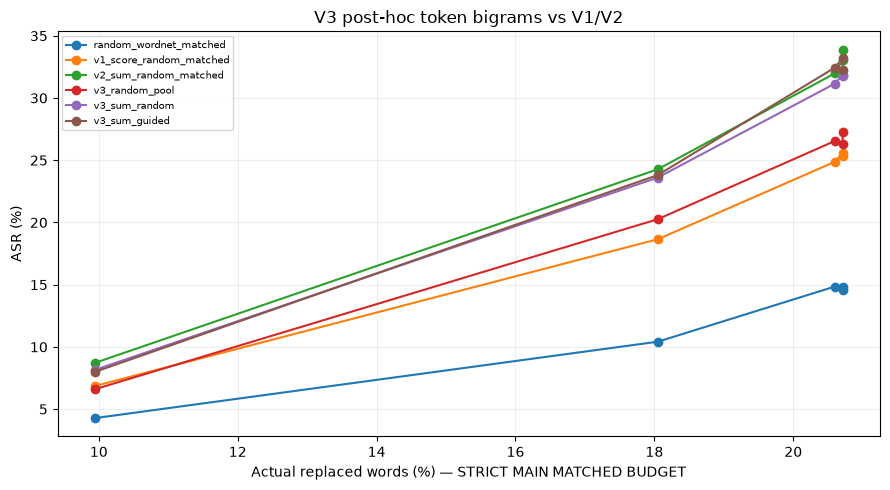

In [24]:
if not coverage_df.empty:
    display(coverage_df.groupby(["min_support", "ratio"], as_index=False).agg(
        coverage_v3=("coverage_v3", "mean"),
        coverage_v2=("coverage_v2", "mean"),
        coverage_v1=("coverage_v1", "mean"),
        coverage_common=("coverage_common", "mean"),
        matched_edit_ratio=("matched_edit_ratio", "mean"),
        common_edit_ratio=("common_edit_ratio", "mean"),
        supported_token_pair_fraction=("supported_token_pair_fraction", "mean"),
    ).round(4))

if not avg.empty:
    guided = avg[avg["method"] == "v3_sum_guided"]
    print("Proportion of actual substitutions supported by token-guided choice:")
    display(guided[["min_support", "ratio", "mean_guided_fraction", "n_splits"]].round(4))

try:
    import matplotlib.pyplot as plt
    if not avg.empty:
        frame = avg[(avg["min_support"] == REFERENCE_SUPPORT) &
                    (avg["comparison_group"] == "main_matched")]
        fig, ax = plt.subplots(figsize=(9, 5))
        for method in ["random_wordnet_matched", "v1_score_random_matched",
                       "v2_sum_random_matched", "v3_random_pool", "v3_sum_random",
                       "v3_sum_guided"]:
            sub = frame[frame["method"] == method].sort_values("ratio")
            if not sub.empty:
                ax.plot(sub["mean_edits"] * 100, sub["mean_asr"] * 100,
                        marker="o", label=method)
        ax.set(xlabel="Actual replaced words (%) — STRICT MAIN MATCHED BUDGET",
               ylabel="ASR (%)", title="V3 post-hoc token bigrams vs V1/V2")
        ax.legend(fontsize=7)
        ax.grid(alpha=0.2)
        fig.tight_layout()
        fig.savefig(OUT_DIR / "v3_asr_vs_actual_edits.png", dpi=160)
        plt.show()
except (ImportError, OSError, RuntimeError, ValueError) as exc:
    print("Optional chart skipped:", repr(exc))

## 11 — Safe CSV exports, manifest, interpretation

Checkpoint JSONLs stay local; commit the notebook, compact CSV/PNG and provenance JSON to GitHub. Derived CSVs may safely grow from a pilot to a full run. No file is silently overwritten if existing split-level observations changed. **Do not claim statistical confirmation from overlapping splits or uncorrected exploratory comparisons.**

In [25]:
def export_csv_consistently(dataframe, filename, sort_keys, allow_updated_aggregates=False):
    """Allow pilot -> full-run growth, while checking prior split-level observations."""
    if dataframe.empty:
        print("Skipped empty export:", filename)
        return
    target = OUT_DIR / filename
    fresh = dataframe.sort_values(sort_keys).reset_index(drop=True)
    assert not fresh.duplicated(sort_keys).any(), (filename, "duplicate keys")
    if target.exists():
        prior = pd.read_csv(target).sort_values(sort_keys).reset_index(drop=True)
        assert list(prior.columns) == list(fresh.columns), (filename, "changed columns")
        assert not prior.duplicated(sort_keys).any(), (filename, "old duplicate keys")
        # Every previously published row must still be present with the same numbers.
        common = fresh.merge(prior[sort_keys], on=sort_keys, how="inner")
        common = common.sort_values(sort_keys).reset_index(drop=True)
        assert len(common) == len(prior), (filename, "previous result disappeared")
        if allow_updated_aggregates:
            assert "n_splits" in fresh.columns
            old_counts = prior[sort_keys + ["n_splits"]].rename(columns={"n_splits": "old_n"})
            compared = common.merge(old_counts, on=sort_keys, how="inner")
            assert (compared["n_splits"] >= compared["old_n"]).all(), "Lost split contributions"
            unchanged_keys = compared.loc[compared["n_splits"].eq(compared["old_n"]), sort_keys]
            if len(unchanged_keys):
                subset_new = common.merge(unchanged_keys, on=sort_keys, how="inner")
                subset_old = prior.merge(unchanged_keys, on=sort_keys, how="inner")
                pd.testing.assert_frame_equal(
                    subset_old.sort_values(sort_keys).reset_index(drop=True),
                    subset_new.sort_values(sort_keys).reset_index(drop=True),
                    check_dtype=False, check_exact=False, rtol=1e-8, atol=1e-8)
        else:
            pd.testing.assert_frame_equal(prior, common, check_dtype=False,
                                          check_exact=False, rtol=1e-8, atol=1e-8)
        if len(prior) == len(fresh) and (not allow_updated_aggregates or
                (common["n_splits"] == prior["n_splits"]).all()):
            print("Verified existing:", filename)
            return
        # Atomic replacement with verified extension (e.g. 1 pilot split -> 10 splits).
        with tempfile.NamedTemporaryFile(mode="w", suffix=".csv", prefix=".new_",
                                         dir=target.parent, delete=False) as handle:
            temp = Path(handle.name)
            fresh.to_csv(handle, index=False)
        temp.replace(target)
        print("Extended safely:", filename, f"({len(prior)} -> {len(fresh)} rows)")
    else:
        dataframe.to_csv(target, index=False)
        print("Saved:", filename)



export_csv_consistently(summary_df, "v3_split_summary.csv",
                        ["min_support", "split_seed", "ratio", "method"])
export_csv_consistently(avg, "v3_asr_aggregates.csv",
                        ["min_support", "ratio", "method"], allow_updated_aggregates=True)
export_csv_consistently(dataset_df, "v3_dataset_breakdown.csv",
                        ["min_support", "split_seed", "ratio", "method", "dataset"])
export_csv_consistently(coverage_df, "v3_coverage.csv",
                        ["min_support", "split_seed", "ratio"])
export_csv_consistently(contrast_df, "v3_contrasts.csv",
                        ["min_support", "split_seed", "ratio", "comparison"])
export_csv_consistently(paired_df, "v3_paired_successes.csv",
                        ["min_support", "split_seed", "ratio", "idx"])
export_csv_consistently(mcnemar_df, "v3_mcnemar_holm.csv",
                        ["min_support", "split_seed", "ratio", "comparison"])

manifest = {
    "experiment_id": EXPERIMENT_ID,
    "input_sha256": input_hashes,
    "tokenizer": config["tokenizer_name"],
    "tokenizer_vocab_sha256": config["tokenizer_vocab_sha256"],
    "alignment_mode": ALIGNMENT_MODE,
    "completed_checkpoints": len(checkpoints),
    "expected_checkpoints": len(SPLIT_SEEDS) * len(MIN_SUPPORTS) * len(RATIOS),
    "pending_checkpoints": missing,
    "methods_matched": METHODS_MATCHED,
    "methods_common_pool": METHODS_COMMON,
    "methods_descriptive": METHODS_DESCRIPTIVE,
    "matched_budget_definition": "min(round(r*n_words),n_V3,n_V2,n_V1) words per text",
    "common_budget_definition": "min(round(r*n_words),n_intersection(V3,V2,V1)) words per text",
    "comparison": "Matched counts do not equate eligible pools; common cohort isolates ranking within intersection",
    "primary_estimand": "ASR on originally detected WM texts, per split",
    "warnings": [
        "Exploratory: overlapping splits, dataset already used to develop V1/V2",
        "Post-hoc retokenization, not original LLaDA generation tokens",
        "No watermark metadata used as attack features",
        "Unsupported token bigrams are unknown, not low-scored",
        "Guided synonyms limited to deterministic subset; report observed guidance fraction",
        "Hybrid not matched in real edit budget",
        "No semantic preservation metric",
    ],
}
manifest_path = OUT_DIR / "v3_manifest.json"
if manifest_path.exists():
    old = json.loads(manifest_path.read_text(encoding="utf-8"))
    fixed = {key: value for key, value in manifest.items()
             if key not in ("completed_checkpoints", "pending_checkpoints")}
    assert all(old.get(key) == value for key, value in fixed.items()), "Manifest provenance mismatch"
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print("\nSaved V3 report manifest:", manifest_path)
if missing:
    print("INCOMPLETE: restore full RUN_* lists, rerun Section 7 onward")
else:
    print("COMPLETE: all planned V3 checkpoints saved and verified")

Extended safely: v3_split_summary.csv (65 -> 1300 rows)
Extended safely: v3_asr_aggregates.csv (65 -> 130 rows)
Extended safely: v3_dataset_breakdown.csv (195 -> 3900 rows)
Extended safely: v3_coverage.csv (5 -> 100 rows)
Extended safely: v3_contrasts.csv (40 -> 800 rows)
Extended safely: v3_paired_successes.csv (975 -> 19400 rows)
Verified existing: v3_mcnemar_holm.csv

Saved V3 report manifest: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v3_token_bigram/v3_manifest.json
COMPLETE: all planned V3 checkpoints saved and verified


## Scientific notes

- **Token window:** The score assigned to a word depends on token-ID bigrams that touch its LLaDA-retokenized span, including edges just outside the span. Tokenization may change around word boundaries after substitution; guided replacement checks changes from a **new full-text tokenization**.
- **V1/V2 parity:** The V1 and V2 scoring, split, WordNet candidate set and support filtering are copied from V2. The V3-only difference is the post-hoc token-bigram signal.
- **Two controls:** Equal *number* of replaced words is not the same as an equal *candidate pool*. Use common-pool results to test whether token scores truly rank positions better.
- **Sparse guided replacements:** Because we refuse to interpret unseen candidate bigrams as low-watermark, guided candidates can be rare. Always report the actual guided rate.
- **Threat model:** The attacker is assumed to have paired WM/NoWM training completions and black-box detection for evaluation. They do **not** use per-token color, mask, ages, greenlist membership, key or generation states.
- **Exploratory inference:** The same 600 prompts and overlapping splits have informed multiple experiments. Exact McNemar on split 42 and Holm correction do not eliminate adaptive-selection bias. Validate an eventual chosen method on a genuinely new dataset if possible.
- **Linguistic fidelity:** WordNet substitutions are not guaranteed semantic-preserving; no fidelity result is claimed.